<a href="https://colab.research.google.com/github/rrohancodes/Imbd_project/blob/main/imbd_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'imdb-dataset-of-top-1000-movies-and-tv-shows' dataset.
Class distribution:
Rating_Class
Low     411
High    302
Name: count, dtype: int64

Accuracy: 0.7132867132867133

Classification Report:

              precision    recall  f1-score   support

        High       0.74      0.51      0.60        61
         Low       0.70      0.87      0.78        82

    accuracy                           0.71       143
   macro avg       0.72      0.69      0.69       143
weighted avg       0.72      0.71      0.70       143


Confusion Matrix:

[[31 30]
 [11 71]]

Top 15 Important Features:

               Feature  Importance
1          No_of_Votes    0.077906
0           Meta_score    0.028389
3              Runtime    0.027179
4        Released_Year    0.024426
179      Director_Freq    0.021413
2                Gross    0.017577
473              world    0.009383
173  Certificate_PG-13    0.008831
304               help    0.008025
175      Certifica

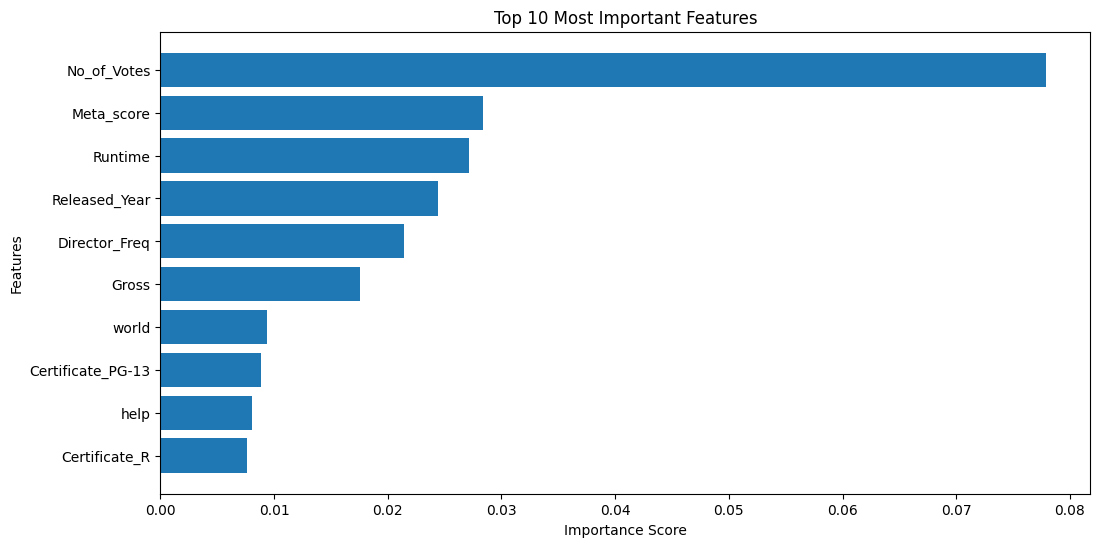

               Minimum      Maximum        Mean      Median  \
Meta_score       28.00       100.00       77.16       78.00   
No_of_Votes   25229.00   2343110.00   356256.76   236311.00   
Gross          1305.00 936662225.00 78379890.50 34700291.00   
Runtime          72.00       238.00      123.69      120.00   
Released_Year  1930.00      2019.00     1995.74     2001.00   
IMDB_Rating       7.60         9.30        7.94        7.90   

               Standard Deviation  
Meta_score                  12.41  
No_of_Votes             354134.56  
Gross                115003113.94  
Runtime                     25.90  
Released_Year               18.60  
IMDB_Rating                  0.29  


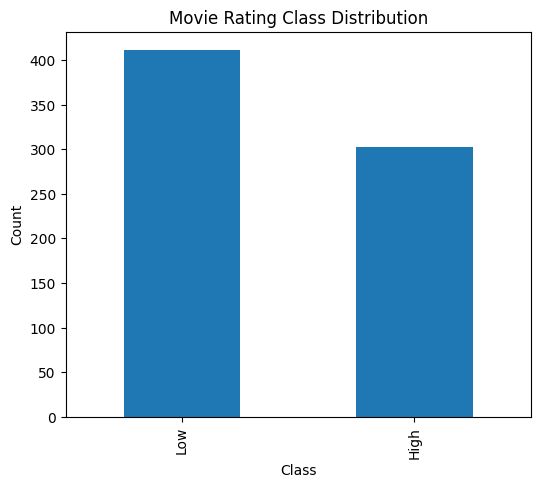

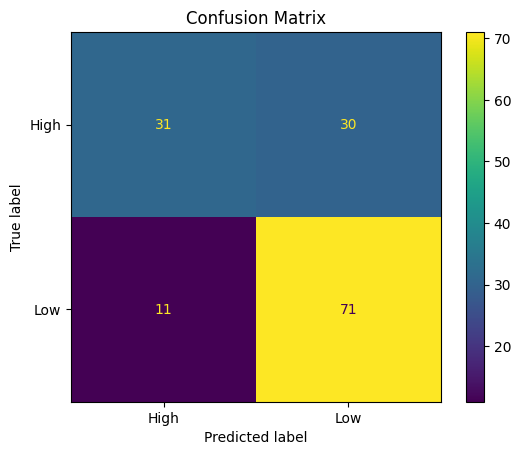

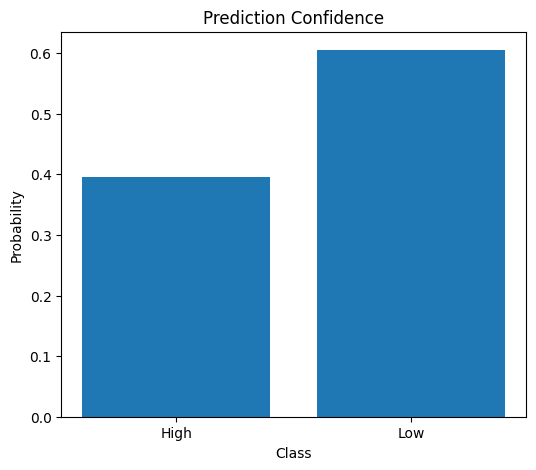

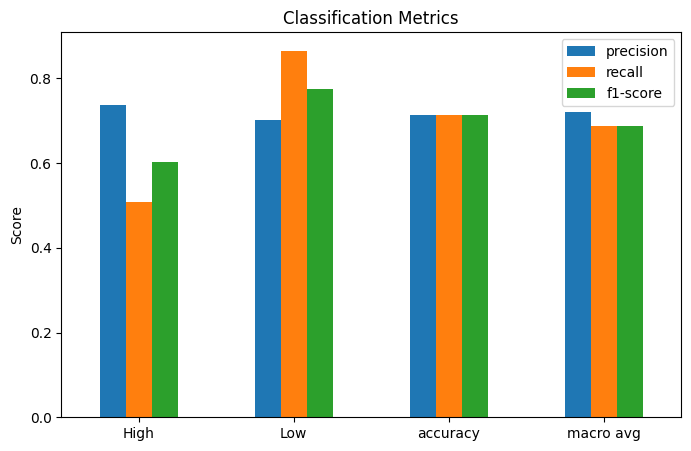

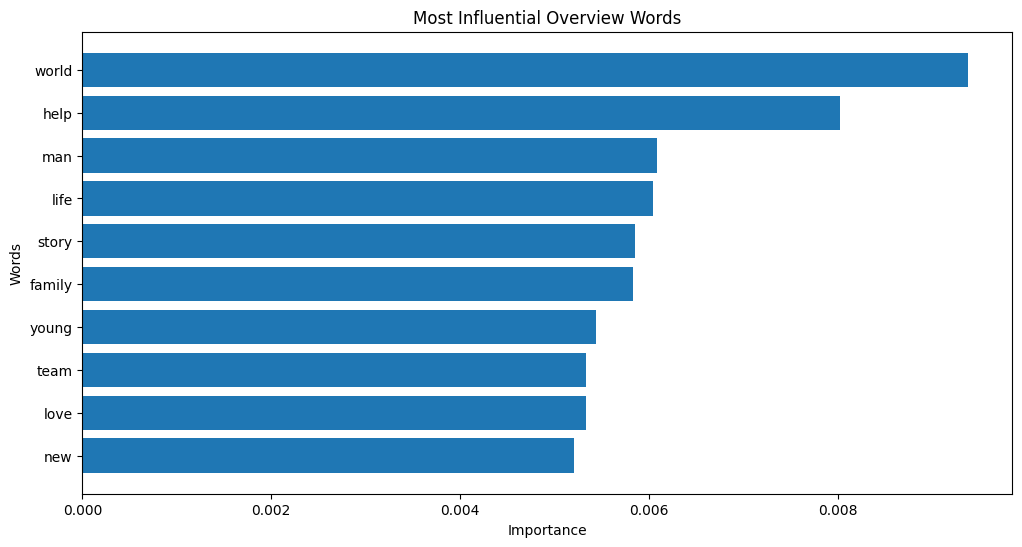

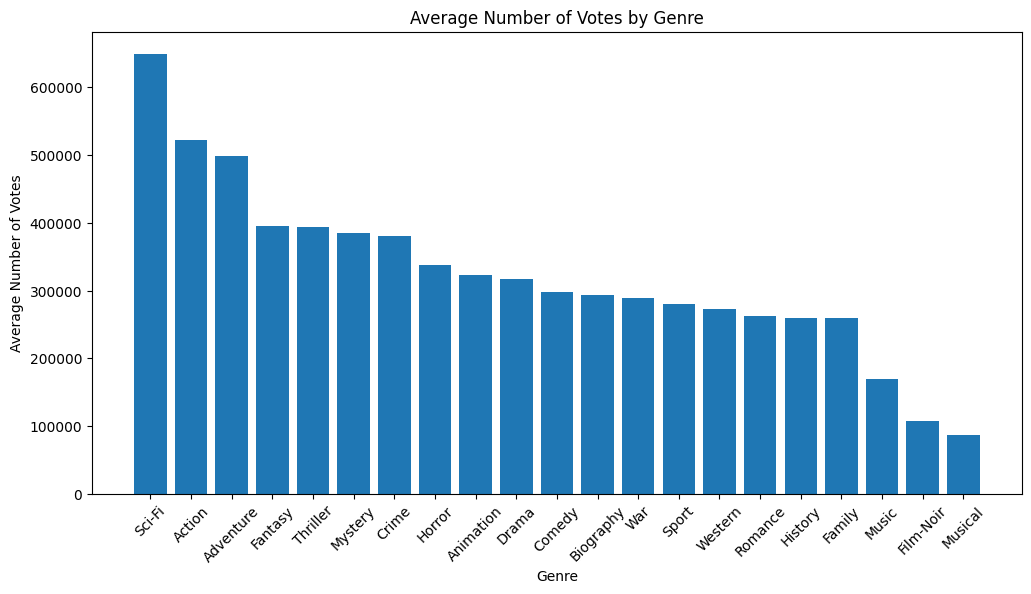

<Figure size 700x500 with 0 Axes>

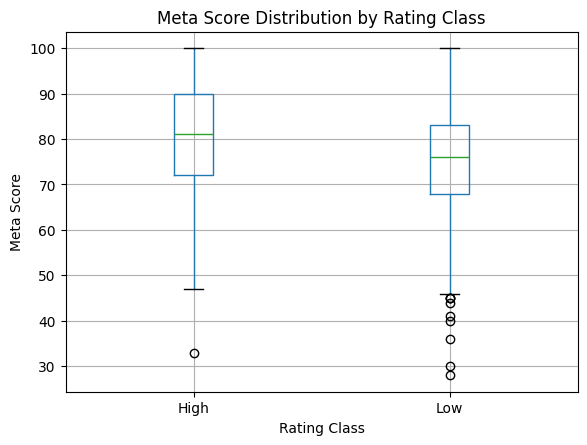

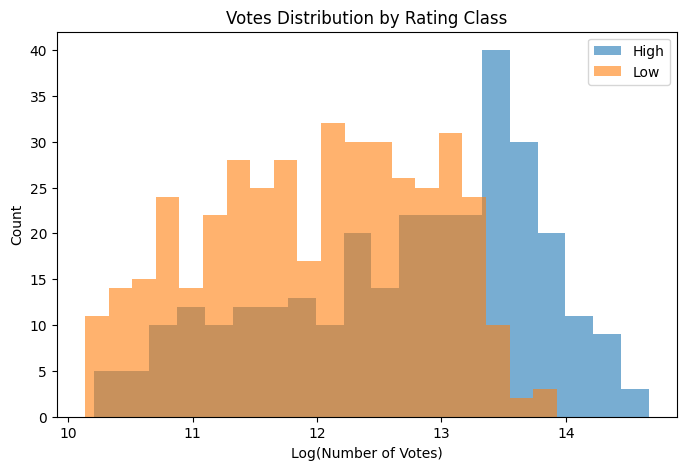

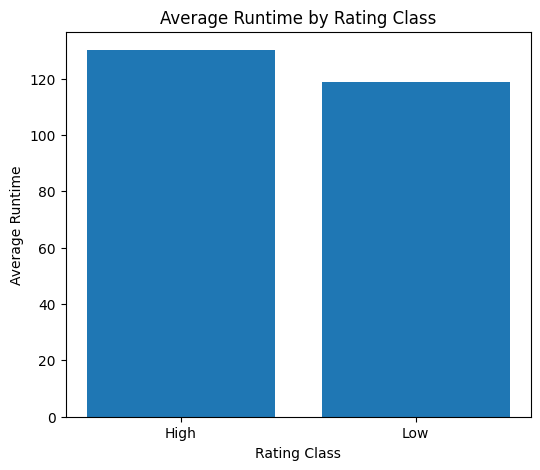

In [ ]:
import pandas as pd
import numpy as np

import kagglehub

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt


# =========================
# CUSTOM DIRECTOR FREQUENCY ENCODER
# =========================
class DirectorFrequencyEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        s = pd.Series(np.array(X).ravel())
        counts = s.value_counts()
        self.freq_map_ = (counts / len(s)).to_dict()
        return self

    def transform(self, X):
        s = pd.Series(np.array(X).ravel())
        return s.map(self.freq_map_).fillna(0.0).values.reshape(-1, 1)


# =========================
# LOAD DATASET
# =========================
path = kagglehub.dataset_download(
    "harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows"
)

fp = path + "/imdb_top_1000.csv"
df = pd.read_csv(fp)

df.columns = df.columns.str.strip()

# =========================
# SELECT FEATURES
# =========================
features = [
    'Meta_score',
    'No_of_Votes',
    'Gross',
    'Runtime',
    'Released_Year',
    'Genre',
    'Certificate',
    'Director',
    'Overview'
]

target = 'IMDB_Rating'
df = df[features + [target]].copy()

# =========================
# CLEAN DATA
# =========================
df['Gross'] = (
    df['Gross']
    .astype(str)
    .str.replace(',', '', regex=False)
)
df['Gross'] = pd.to_numeric(df['Gross'], errors='coerce')

df['Runtime'] = (
    df['Runtime']
    .astype(str)
    .str.replace(' min', '', regex=False)
)
df['Runtime'] = pd.to_numeric(df['Runtime'], errors='coerce')

df['Released_Year'] = pd.to_numeric(df['Released_Year'], errors='coerce')
df['Meta_score'] = pd.to_numeric(df['Meta_score'], errors='coerce')
df['No_of_Votes'] = pd.to_numeric(df['No_of_Votes'], errors='coerce')

# Reduce skew
df['No_of_Votes'] = np.log1p(df['No_of_Votes'])
df['Gross'] = np.log1p(df['Gross'])

# Drop rows with missing values
df = df.dropna().copy()

# =========================
# CREATE BINARY TARGET
# =========================
threshold = df['IMDB_Rating'].median()

df['Rating_Class'] = np.where(
    df['IMDB_Rating'] > threshold,
    'High',
    'Low'
)

print("Class distribution:")
print(df['Rating_Class'].value_counts())

# =========================
# DEFINE X AND y
# =========================
X = df.drop(columns=['IMDB_Rating', 'Rating_Class'])
y = df['Rating_Class']

# =========================
# TRAIN TEST SPLIT
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# =========================
# PREPROCESSING
# =========================
numeric_features = [
    'Meta_score',
    'No_of_Votes',
    'Gross',
    'Runtime',
    'Released_Year'
]

categorical_features = [
    'Genre',
    'Certificate'
]



director_feature = ['Director']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

director_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('freq', DirectorFrequencyEncoder())
])

text_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value=''
    )),

    # Convert 2D -> 1D
    ('flatten', FunctionTransformer(
        lambda x: x.ravel(),
        validate=False
    )),

    ('tfidf', TfidfVectorizer(
        max_features=300,
        stop_words='english'
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
        ('dir', director_transformer, director_feature),
        ('text', text_transformer, ['Overview'])
    ]
)

# =========================
# MODEL
# =========================
model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', model)
])

# =========================
# TRAIN
# =========================
pipeline.fit(X_train, y_train)

# =========================
# PREDICT
# =========================
y_pred = pipeline.predict(X_test)

# =========================
# EVALUATION
# =========================
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

# =========================
# FEATURE IMPORTANCE
# =========================

# Numeric feature names
numeric_names = numeric_features

# Categorical one-hot names
cat_names = pipeline.named_steps[
    'preprocess'
].named_transformers_[
    'cat'
].named_steps[
    'onehot'
].get_feature_names_out(categorical_features)

# Director frequency feature
director_name = ['Director_Freq']

# TF-IDF text feature names
text_names = pipeline.named_steps[
    'preprocess'
].named_transformers_[
    'text'
].named_steps[
    'tfidf'
].get_feature_names_out()

# Combine ALL names
feature_names = np.concatenate([
    numeric_names,
    cat_names,
    director_name,
    text_names
])

# Model importances
importances = pipeline.named_steps[
    'model'
].feature_importances_

# Create dataframe
importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort descending
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop 15 Important Features:\n")

print(importance.head(15))

# =========================
# VISUALIZATION
# TOP INFORMATIVE ATTRIBUTES ONLY
# =========================
top_features = importance.head(10)

plt.figure(figsize=(12,6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.title("Top 10 Most Important Features")

plt.gca().invert_yaxis()

plt.show()

pd.set_option('display.float_format', '{:.2f}'.format)
temp_df = df.copy()

temp_df['No_of_Votes'] = np.expm1(
    temp_df['No_of_Votes']
)

temp_df['Gross'] = np.expm1(
    temp_df['Gross']
)

numeric_columns = [
    'Meta_score',
    'No_of_Votes',
    'Gross',
    'Runtime',
    'Released_Year',
    'IMDB_Rating'
]

range_df = pd.DataFrame({

    'Minimum': temp_df[numeric_columns].min(),

    'Maximum': temp_df[numeric_columns].max(),

    'Mean': temp_df[numeric_columns].mean(),

    'Median': temp_df[numeric_columns].median(),

    'Standard Deviation': temp_df[numeric_columns].std()
})

print(range_df)

plt.figure(figsize=(6,5))

df['Rating_Class'].value_counts().plot(
    kind='bar'
)

plt.xlabel("Class")
plt.ylabel("Count")

plt.title("Movie Rating Class Distribution")

plt.show()

from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=pipeline.classes_
)

disp.plot()

plt.title("Confusion Matrix")

plt.show()



movie_probs = probabilities[0]

plt.figure(figsize=(6,5))

plt.bar(
    classes,
    movie_probs
)

plt.xlabel("Class")
plt.ylabel("Probability")

plt.title("Prediction Confidence")

plt.show()



report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

metrics_df = pd.DataFrame(report).transpose()

metrics_df = metrics_df.iloc[:-1]

metrics_df[['precision', 'recall', 'f1-score']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Classification Metrics")

plt.ylabel("Score")

plt.xticks(rotation=0)

plt.show()



text_features = importance[
    importance['Feature'].isin(text_names)
]

top_text = text_features.head(10)

plt.figure(figsize=(12,6))

plt.barh(
    top_text['Feature'],
    top_text['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Words")

plt.title("Most Influential Overview Words")

plt.gca().invert_yaxis()

plt.show()

# =========================
# GENRE VS NUMBER OF VOTES
# =========================

genre_df = df[['Genre', 'No_of_Votes']].copy()

# Convert log values back to original scale
genre_df['No_of_Votes'] = np.expm1(
    genre_df['No_of_Votes']
)

# Split multiple genres
genre_df['Genre'] = genre_df['Genre'].str.split(',')

genre_df = genre_df.explode('Genre')

# Remove spaces
genre_df['Genre'] = genre_df['Genre'].str.strip()

# Average votes by genre
genre_votes = (
    genre_df.groupby('Genre')['No_of_Votes']
    .mean()
    .sort_values(ascending=False)
)

# Plot
plt.figure(figsize=(12,6))

plt.bar(
    genre_votes.index,
    genre_votes.values
)

plt.xticks(rotation=45)

plt.xlabel("Genre")
plt.ylabel("Average Number of Votes")

plt.title("Average Number of Votes by Genre")

plt.show()


plt.figure(figsize=(7,5))

df.boxplot(
    column='Meta_score',
    by='Rating_Class'
)

plt.title("Meta Score Distribution by Rating Class")

plt.suptitle("")

plt.xlabel("Rating Class")
plt.ylabel("Meta Score")

plt.show()


high_votes = df[
    df['Rating_Class'] == 'High'
]['No_of_Votes']

low_votes = df[
    df['Rating_Class'] == 'Low'
]['No_of_Votes']

plt.figure(figsize=(8,5))

plt.hist(
    high_votes,
    bins=20,
    alpha=0.6,
    label='High'
)

plt.hist(
    low_votes,
    bins=20,
    alpha=0.6,
    label='Low'
)

plt.xlabel("Log(Number of Votes)")
plt.ylabel("Count")

plt.title("Votes Distribution by Rating Class")

plt.legend()

plt.show()


runtime_avg = df.groupby(
    'Rating_Class'
)['Runtime'].mean()

plt.figure(figsize=(6,5))

plt.bar(
    runtime_avg.index,
    runtime_avg.values
)

plt.xlabel("Rating Class")
plt.ylabel("Average Runtime")

plt.title("Average Runtime by Rating Class")

plt.show()

In [ ]:
# =========================
# CUSTOM MOVIE PREDICTION
# =========================

high_movie = pd.DataFrame({

    'Meta_score': [92],

    'No_of_Votes': [np.log1p(100000)],

    'Gross': [np.log1p(850000000)],

    'Runtime': [165],

    'Released_Year': [2023],

    'Genre': ['Musical'],

    'Certificate': ['UA'],

    'Director': ['Christopher Nolan'],

    'Overview': [
    'A highly skilled detective uncovers a massive political conspiracy while investigating a series of mysterious murders that threaten the stability of the nation.'
    ]
})

low_movie = pd.DataFrame({

    'Meta_score': [35],

    'No_of_Votes': [np.log1p(1200)],

    'Gross': [np.log1p(500000)],

    'Runtime': [92],

    'Released_Year': [2024],

    'Genre': ['Horror'],

    'Certificate': ['A'],

    'Director': ['Unknown Director'],

    'Overview': [
        'A group of teenagers get trapped in an abandoned building and try to survive strange paranormal events.'
    ]
})

# Predict class
prediction = pipeline.predict(low_movie)

print("Predicted Class:", prediction[0])

# Predict probabilities
probabilities = pipeline.predict_proba(low_movie)

# Get class labels
classes = pipeline.classes_

print("\nPrediction Confidence for low:\n")

for cls, prob in zip(classes, probabilities[0]):

    print(
        cls,
        ":",
        round(prob * 100, 2),
        "%"
    )



prediction = pipeline.predict(high_movie)

print("Predicted Class:", prediction[0])

# Predict probabilities
probabilities = pipeline.predict_proba(high_movie)

# Get class labels
classes = pipeline.classes_

print("\nPrediction Confidence for high:\n")

for cls, prob in zip(classes, probabilities[0]):

    print(
        cls,
        ":",
        round(prob * 100, 2),
        "%"
    )



Predicted Class: Low

Prediction Confidence for low:

High : 16.5 %
Low : 83.5 %
Predicted Class: Low

Prediction Confidence for high:

High : 39.5 %
Low : 60.5 %
